In [407]:
import numpy as np
import matplotlib.pyplot as plt

In [408]:
class Memristor():
    def __init__(self, x_start=0.5, R_on=100.0, R_off=1600.0, k=0*1e8,p=2):
        """
        модель Вудса-Уиллиса
        - x: текущее состояние (0..1)
        - R_on, R_off: минимальное и максимальное сопротивление (Ом)
        - k: коэффициент скорости изменения состояния
        """
        self.x = x_start
        self.R_on = R_on
        self.R_off = R_off
        self.k = k
        self.p = 1

    def get_R(self):
        return self.R_off + (self.R_on - self.R_off) * self.x

    def get_x(self):
        return self.x * 1.

    def upd_x(self, dq):
        self.x += self.k * dq * (1 - (2*self.x - 1)**self.p)
        self.x = max(min(0.99, self.x), 0.01)

In [409]:
# ----------------------------
# Параметры схемы и моделирования
# ----------------------------
T = 1e-1                # время моделирования, с
dt = 1e-5                # шаг по времени, с
N = int(T/dt)

# Характеристики элементов
mem = Memristor(x_start=0.99) # мемристор
C_c = 10**-4
V_inv = 0 # -0.1
I_inv = 10**(-4)

# Источник тока
t = np.linspace(0, T, N)
# I_in = np.zeros(N)
# I_in = 10**(-3) * np.ones(N)
I_in = 10**(-3) * (np.exp(-((t - 10*T/100)/(T/100))**2) + np.exp(-((t - 15*T/100)/(T/100))**2))


# Массивы для результатов
x_mem = np.zeros(N)
V_out = np.zeros(N)
I_mem = np.zeros(N)
I_c = np.zeros(N)

In [410]:
# ----------------------------
# Цикл вычислений
# ----------------------------
# V_out[0] = V_inv
# I_mem[0] = 0
# I_c[0] = 0
# x_mem[0] = mem.get_x()

I_mem[0] = - I_inv
I_c[0] = 0
V_out[0] = V_inv + I_mem[0] * Rm
x_mem[0] = mem.get_x()

for i in range(N-1):
    Rm = mem.get_R()
    I_mem[i+1] = (V_out[i] - V_inv) / Rm
    I_c[i+1] = I_in[i+1] - I_mem[i+1] - I_inv
    V_out[i+1] = V_out[i] + I_c[i+1] * dt / C_c
    
    mem.upd_x(- I_mem[i+1] * dt)
    x_mem[i+1] = mem.get_x()

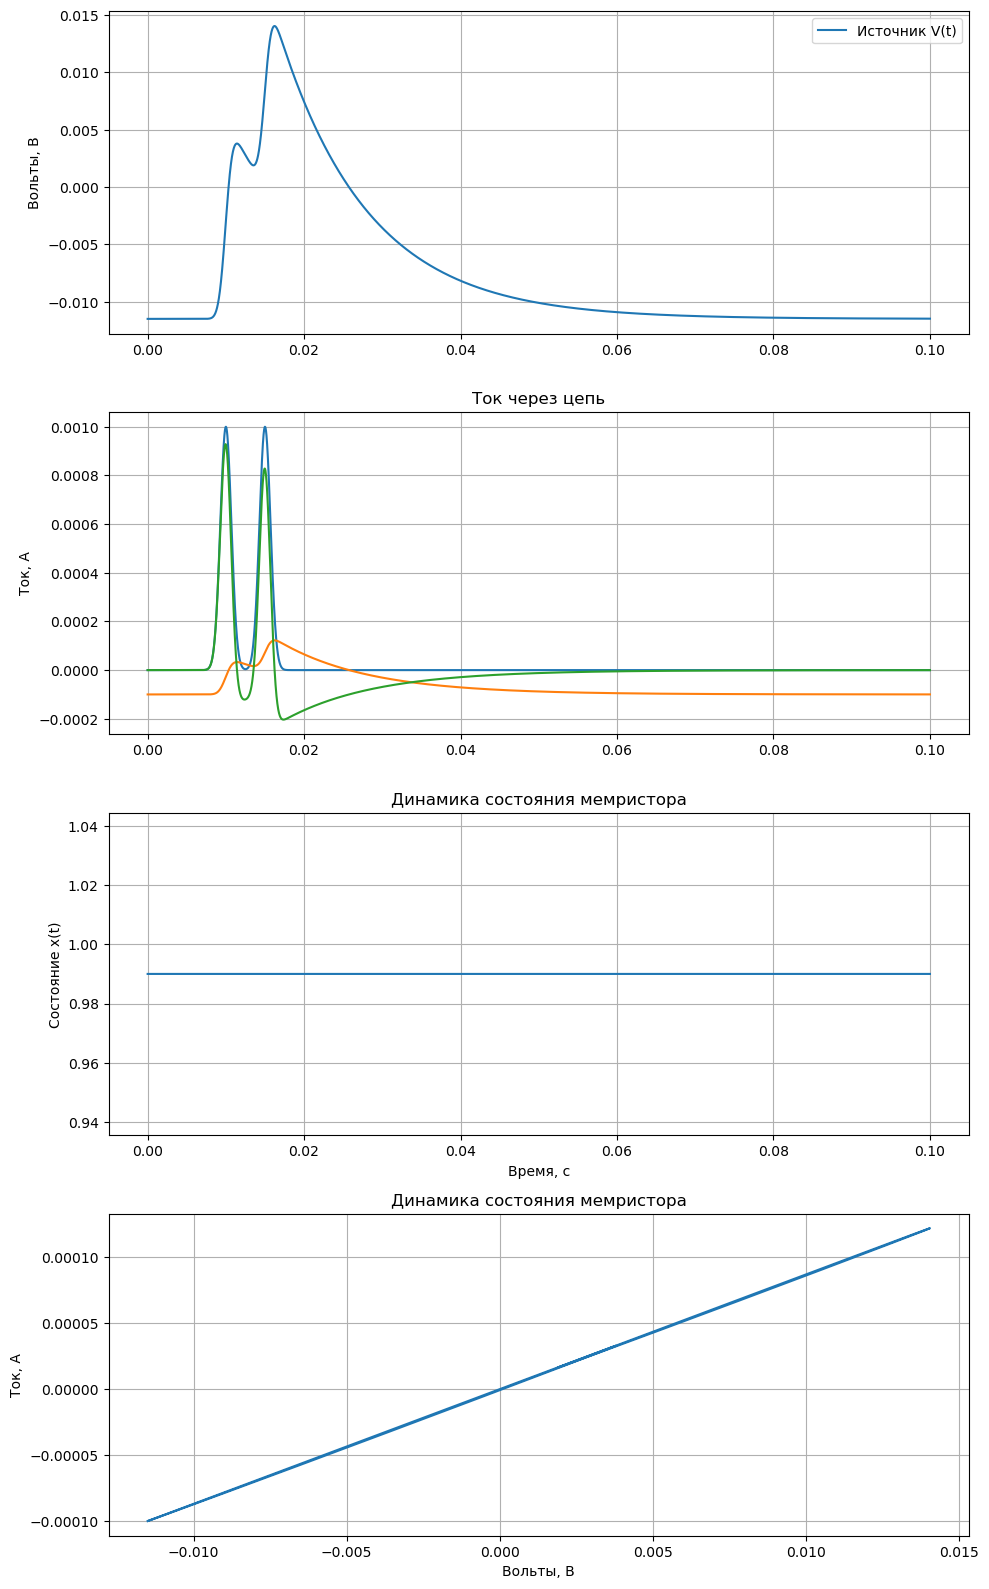

In [411]:
# ----------------------------
# Вывод графиков
# ----------------------------
plt.figure(figsize=(10, 16))

plt.subplot(4, 1, 1)
plt.plot(t, V_out, label='Источник V(t)')
plt.ylabel('Вольты, В')
plt.legend()
plt.grid(True)

plt.subplot(4, 1, 2)
plt.plot(t, I_in)
plt.plot(t, I_mem)
plt.plot(t, I_c)
plt.ylabel('Ток, А')
plt.title('Ток через цепь')
plt.grid(True)

plt.subplot(4, 1, 3)
plt.plot(t, x_mem)
plt.xlabel('Время, с')
plt.ylabel('Состояние x(t)')
plt.title('Динамика состояния мемристора')
plt.grid(True)

plt.subplot(4, 1, 4)  
plt.plot(V_out - V_inv, I_mem)
plt.xlabel('Вольты, В')
plt.ylabel('Ток, А')
plt.title('Динамика состояния мемристора')
plt.grid(True)
plt.tight_layout()
plt.show()